# CFM 301 Project 4: Credit Spreads and Treasury Liquidity

**Reproducing and extending Ch. 9 (Bonds), slide 59: "Baa-Tsy Yield Spreads and Liquidity" (Corr = 0.96)**

## 1. Economic question and intended audience

**Question.** How much of the corporate credit spread reflects *market liquidity* rather than *default risk*, and does the near-perfect co-movement between the Baa-Treasury spread and Treasury liquidity on slide 59 hold outside the 2007–2009 financial crisis?

**Why it matters.** The Merton model says credit spreads compensate investors for default risk, which rises with firm asset volatility. If spreads instead move mainly with market-wide liquidity, then a large part of a spread blow-out is not about firms becoming more likely to default. It is about investors being unable or unwilling to hold illiquid assets. That distinction decides the right policy response: a liquidity facility can compress liquidity-driven spreads, but it cannot fix default risk.

**Audience.** Central-bank policymakers who design market-liquidity facilities (the Bank of Canada's Corporate Bond Purchase Program and the Fed's 2020 corporate credit facilities are examples), and corporate bond fund managers deciding whether wide spreads are a buying opportunity (liquidity) or a warning (default risk).

**Notebook map:** setup (§2) → data and cleaning (§3–4) → slide-window figure (§5) → extended sample (§6) → comparison to slide 59 (§7) → liquidity vs. default-risk regressions (§8) → credit spread puzzle (§9) → sensitivity analysis (§10) → conclusion (§11).

## 2. Setup

**How to run (reproducibility).**

1. Keep this structure: `spread.ipynb` next to a `Data/` folder that contains the seven input files listed in §3.
2. Open the notebook from the `Bond Yield Spread` folder (or from the repository root; both work) and choose **Restart & Run All**.
3. The notebook reads only local files with relative paths. It needs no WRDS login, no internet connection and no manual step. It writes no output files: every table and figure appears below.

**Software:** Python 3.11+ with `pandas`, `numpy`, `matplotlib`, and `xlrd` (pandas needs it to read the two Treasury `.xls` files; newer pandas versions can use `python-calamine` instead). Install with `pip install pandas numpy matplotlib xlrd`. The first code cell prints the exact versions used. Regressions use a Newey-West estimator written in NumPy below, so `statsmodels` is not required. Runtime: a few seconds.

In [29]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}')

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)

# Works whether the notebook is started from its own folder or from the repository root.
DATA_DIR = Path('Data') if Path('Data').exists() else Path('Bond Yield Spread') / 'Data'
assert DATA_DIR.exists(), 'Data folder not found: run the notebook from the "Bond Yield Spread" folder.'

FILES = {
    'BAA':   'BAA (1).csv',      # Moody's seasoned Baa corporate bond yield (FRED), monthly average, %
    'GS20':  'GS20.csv',         # 20-year Treasury constant-maturity yield (FRED), monthly average, %
    'TB3MS': 'TB3MS (1).csv',    # 3-month T-bill secondary-market rate (FRED), monthly average, %
    'VIX':   'VIXCLS.csv',       # CBOE VIX (FRED), daily close, index points
    'OFF':   'Treasury yields month end off the run.xls',  # US Treasury TNC off-the-run par yield curve, month-end, %
    'ON':    'Treasury yields month end on the run.xls',   # US Treasury TNC on-the-run par yield curve, month-end, %
}

# Key sample dates
SLIDE_START, SLIDE_END = '2006-01', '2009-10'   # slide 59's sample (read from the chart data embedded in the Ch. 9 slides)
GFC_START, GFC_END = '2007-08', '2009-06'       # crisis window: BNP Paribas fund freeze (Aug 2007) to NBER trough (Jun 2009)

# NBER recession months (peak month excluded, trough month included, as in FRED's USREC series). Source: nber.org/research/business-cycle-dating
NBER_RECESSIONS = [('1990-08', '1991-03'), ('2001-04', '2001-11'), ('2008-01', '2009-06'), ('2020-03', '2020-04')]

Python 3.11.4 | pandas 2.0.3 | numpy 1.24.3 | matplotlib 3.7.1


### Helper functions

OLS with **Newey-West (HAC)** standard errors is coded directly in NumPy (Bartlett kernel, small-sample correction n/(n−k)), so the notebook needs no extra packages. HAC errors are needed because the spread, the liquidity proxy and VIX are all highly persistent: each month's value is close to last month's, so ordinary OLS t-statistics would be far too large.

In [30]:
def ols_hac(y, X, lags=12):
    """OLS of y on [1, X] with Newey-West (Bartlett) standard errors.
    Returns a dict with coefficients, HAC t-stats, R-squared and N."""
    data = pd.concat([y, X], axis=1).dropna()
    yv = data.iloc[:, 0].to_numpy(float)
    names = ['const'] + list(data.columns[1:])
    Xv = np.column_stack([np.ones(len(data)), data.iloc[:, 1:].to_numpy(float)])
    n, k = Xv.shape
    XtX_inv = np.linalg.inv(Xv.T @ Xv)
    beta = XtX_inv @ Xv.T @ yv
    u = yv - Xv @ beta
    Xu = Xv * u[:, None]
    S = Xu.T @ Xu
    for lag in range(1, lags + 1):
        weight = 1 - lag / (lags + 1)
        gamma = Xu[lag:].T @ Xu[:-lag]
        S += weight * (gamma + gamma.T)
    cov = n / (n - k) * XtX_inv @ S @ XtX_inv
    se = np.sqrt(np.diag(cov))
    r2 = 1 - (u @ u) / ((yv - yv.mean()) @ (yv - yv.mean()))
    return {'coef': pd.Series(beta, names), 't': pd.Series(beta / se, names), 'r2': r2, 'n': n,
            'start': data.index.min(), 'end': data.index.max()}

def corr_n(a, b):
    """Correlation and number of overlapping observations."""
    pair = pd.concat([a, b], axis=1).dropna()
    return pair.iloc[:, 0].corr(pair.iloc[:, 1]), len(pair)

def in_periods(index, periods):
    """Boolean mask: True for months inside any (start, end) period."""
    mask = pd.Series(False, index=index)
    for start, end in periods:
        mask |= (index >= pd.Period(start, 'M')) & (index <= pd.Period(end, 'M'))
    return mask

def shade_recessions(ax, start=None, end=None):
    for a, b in NBER_RECESSIONS:
        a, b = pd.Period(a, 'M'), pd.Period(b, 'M')
        if (start is None or b >= pd.Period(start, 'M')) and (end is None or a <= pd.Period(end, 'M')):
            ax.axvspan(a.to_timestamp(), b.to_timestamp(how='end'), color='grey', alpha=0.15, lw=0)

def dual_axis_plot(spread, liquidity, title, start=None, end=None, recessions=True, ax=None,
                   spread_label='Baa − 20y off-the-run Treasury spread (left, %)',
                   liq_label='Off-the-run − on-the-run 10y, monthly avg. (right, bp)'):
    s, l = spread.loc[start:end], liquidity.loc[start:end]
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(s.index.to_timestamp(), s, color='black', lw=1.8, label=spread_label)
    ax.set_ylabel('Baa − Treasury spread (%)')
    ax2 = ax.twinx()
    ax2.plot(l.index.to_timestamp(), l, color='tab:red', ls='--', lw=1.5, label=liq_label)
    ax2.set_ylabel('On/off-the-run spread (bp)', color='tab:red')
    ax2.tick_params(axis='y', colors='tab:red')
    if recessions:
        shade_recessions(ax, start, end)
    rho, n = corr_n(s, l)
    ax.set_title(f'{title}\nCorrelation = {rho:.2f} (N = {n} months)')
    lines_ = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
    ax.legend(lines_, [h.get_label() for h in lines_], loc='upper left', fontsize=9)
    ax.grid(alpha=0.25)
    return ax, ax2

## 3. Data sources (requirement 2)

| Series | File | Source | Native frequency | Units | Coverage in file |
|---|---|---|---|---|---|
| Moody's seasoned Baa corporate bond yield | `BAA (1).csv` | FRED (`BAA`), from Fed H.15 / Moody's | Monthly average of daily yields | % | 1919 – Oct 2026 |
| 20-year Treasury yield | `GS20.csv` | FRED (`GS20`) | Monthly average | % | 1953 – Oct 2026 (no data Jan 1987 – Sep 1993) |
| 3-month T-bill | `TB3MS (1).csv` | FRED (`TB3MS`) | Monthly average | % | 1934 – Oct 2026 |
| VIX | `VIXCLS.csv` | FRED (`VIXCLS`), CBOE | Daily close | Index points | Jan 1990 – Oct 2026 |
| Off-the-run Treasury par yields (2, 3, 5, 7, 10, 20, 30y) | `Treasury yields month end off the run.xls` | U.S. Treasury, Treasury Nominal Coupon-Issue (TNC) yield curve | Month-end | % | Jan 1976 – Sep 2026 |
| On-the-run Treasury par yields (2, 5, 10y) | `Treasury yields month end on the run.xls` | U.S. Treasury, TNC on-the-run yield curve | Month-end | % | Jan 1986 – Sep 2026 |
| Baa default loss rate and recovery rate | hard-coded (§9) | Ch. 9 slides 55–57 (Moody's; Giesecke et al., 2011) | Averages | % | 1982–2008; 1866–2008 |

**Construction (requirement 3):**

| Series | Definition | Units | Maturity | Frequency |
|---|---|---|---|---|
| **Credit spread (baseline)** | Moody's Baa yield − off-the-run **20-year** Treasury par yield | percentage points | 20–30y vs. 20y: **matched** | Monthly average |
| **Liquidity proxy (baseline)** | (off-the-run 10y par yield − on-the-run 10y par yield) × 100 | basis points | 10y vs. 10y: **matched** | Monthly average |
| **Default-risk proxy** | VIX | index points | 30-day implied volatility | Monthly average of daily closes |

**Maturity matching.** Moody's seasoned Baa index holds bonds with remaining maturities as close as possible to 30 years, and drops a bond once it falls below 20 years. The Treasury leg must therefore be a long bond. We use the **20-year off-the-run par yield** from the U.S. Treasury's TNC curve, because:
1. **It matches maturity.** 20 years lies inside Baa's 20–30-year range.
2. **It has no gap.** FRED's `GS20` is missing from Jan 1987 to Sep 1993, when Treasury issued no 20-year bonds. It is also unreliable in 1986, up to about 1 pp below the TNC 20-year yield, because it rested on a few old bonds. The TNC series is continuous from 1976. Splicing GS20 with another source would create an artificial break of about 0.6–0.9 pp at Jan 1987.
3. **It keeps the liquidity premium out of the spread.** On-the-run yields are pushed down by the liquidity premium. If the Treasury leg were an on-the-run yield (or a constant-maturity yield built mainly from on-the-run issues), the spread would contain the liquidity proxy itself: Baa − on-the-run = (Baa − off-the-run) + liquidity. That would inflate the correlation mechanically. Off-the-run yields are slightly *cheap* instead, which biases our correlation slightly *down*, so our estimates are conservative.

**Alternatives kept for comparison:**
- **Baa − `GS20`** (gap months dropped, not filled) and **Baa − 30-year off-the-run** are alternative matched maturities (§10).
- **Baa − 3-month T-bill** is a deliberately mismatched diagnostic.

**Liquidity proxy.** The on-the-run note is the newest, most-traded 10-year issue. Investors pay a premium for it, so its yield is lower than an otherwise identical older bond's, and the gap widens when investors scramble for liquidity. Both legs come from the same Treasury TNC data, so they are built the same way and at the same 10-year maturity. The spread (20y) and the liquidity proxy (10y) do not need the same maturity: the proxy measures *market-wide* Treasury liquidity stress, and the 10-year note is the market's main benchmark. §10 shows that 2- and 5-year versions of the proxy do not work.

**Common frequency = monthly averages.** Moody's Baa, the FRED yields and VIX are monthly averages of daily data. The Treasury TNC files contain only month-end values, so we convert them to an approximate monthly average: the mean of this month-end and last month-end. This puts every baseline series on the same timing. The first month of each TNC series is lost (Jan 1976 for the off-the-run curve, Jan 1986 for the on-the-run curve). §10 shows that using raw month-end values instead changes nothing.

In [31]:
def read_fred(key):
    raw = pd.read_csv(DATA_DIR / FILES[key], na_values='.')
    raw['observation_date'] = pd.to_datetime(raw['observation_date'])
    return raw

def read_tnc(key):
    """Read a Treasury TNC .xls sheet; returns (raw rows, tidy DataFrame indexed by month)."""
    path = DATA_DIR / FILES[key]
    try:
        raw = pd.read_excel(path, header=None)
    except ImportError:                     # .xls needs xlrd; newer pandas can fall back to calamine
        try:
            raw = pd.read_excel(path, header=None, engine='calamine')
        except Exception as err:
            raise ImportError('Reading .xls files needs the xlrd package: pip install xlrd') from err
    header_row = raw.index[raw.iloc[:, 2].astype(str).str.contains('Years', na=False)][0]
    maturities = [int(str(v).split()[0]) for v in raw.iloc[header_row, 2:] if pd.notna(v)]
    body = raw.iloc[header_row + 1:, [0] + list(range(2, 2 + len(maturities)))]
    body.columns = ['date'] + maturities
    return raw, header_row, body

raw = {k: read_fred(k) for k in ['BAA', 'GS20', 'TB3MS', 'VIX']}
tnc_raw = {k: read_tnc(k) for k in ['OFF', 'ON']}

overview = []
for k, df in raw.items():
    col = df.columns[1]
    overview.append({'Series': k, 'Rows': len(df), 'First': df['observation_date'].min().date(),
                     'Last': df['observation_date'].max().date(), 'Missing values': int(df[col].isna().sum())})
for k, (r, h, body) in tnc_raw.items():
    dates = pd.to_datetime(body['date'], format='%b %Y', errors='coerce')
    overview.append({'Series': f'{k}-the-run curve ({", ".join(str(m) for m in body.columns[1:])}y)', 'Rows': len(r),
                     'First': dates.min().date(), 'Last': dates.max().date(),
                     'Missing values': int(body.iloc[:, 1:].isna().all(axis=1).sum())})  # rows with no yields = trailing note rows
display(pd.DataFrame(overview).set_index('Series'))

,Rows,First,Last,Missing values
Series,,,,
BAA,1294,1919-01-01,2026-10-01,0
GS20,883,1953-04-01,2026-10-01,81
TB3MS,1114,1934-01-01,2026-10-01,0
VIX,9606,1990-01-02,2026-10-27,302
"OFF-the-run curve (2, 3, 5, 7, 10, 20, 30y)",615,1976-01-01,2026-09-01,1
"ON-the-run curve (2, 5, 10y)",495,1986-01-01,2026-09-01,1


## 4. Data cleaning (requirement 4)

Each step is applied to every series, and the cleaning log at the end of this section counts the observations each step affects.

1. **Non-data rows** in the Treasury spreadsheets (title, header and blank lines) are removed.
2. **Missing values:** FRED marks holidays and unavailable days with "." (for example VIX on market holidays). FRED's `GS20` is blank from 1987 to 1993 because Treasury did not issue 20-year bonds then. Missing values are **dropped, not filled or interpolated**. Filling would invent yields. The baseline avoids the `GS20` gap altogether by using the continuous TNC 20-year series (§3).
3. **Duplicates:** duplicate dates are checked and removed (keeping the first record).
4. **Plausibility checks:** yields must lie between −1% and 25%. VIX must be positive. The liquidity proxy must be within ±200 bp.
5. **Common frequency:** daily VIX is averaged within each calendar month (at least 10 trading days required). Month-end TNC yields are converted to approximate monthly averages (mean of adjacent month-ends).
6. **Outliers:** flagged at the 1st/99th percentiles and |z| > 3 within the analysis sample.
7. **Alignment:** all series are joined on a monthly `Period` index. The analysis sample is the set of months where the Baa spread and the liquidity proxy both exist.

In [32]:
log = []   # cleaning log: (step, series, observations affected)
monthly = {}

# Steps 2-3 for FRED monthly series
for key in ['BAA', 'GS20', 'TB3MS']:
    df = raw[key].copy()
    col = df.columns[1]
    n_missing = int(df[col].isna().sum())
    df = df.dropna(subset=[col])
    df['month'] = df['observation_date'].dt.to_period('M')
    n_dup = int(df['month'].duplicated().sum())
    df = df.drop_duplicates('month')
    bad = ~df[col].between(-1, 25)
    df = df[~bad]
    log += [('2. Missing values dropped', key, n_missing), ('3. Duplicate months removed', key, n_dup),
            ('4. Implausible values removed', key, int(bad.sum()))]
    monthly[key] = df.set_index('month')[col].astype(float).sort_index()

# VIX: daily -> monthly
vix_daily = raw['VIX'].copy()
n_missing = int(vix_daily['VIXCLS'].isna().sum())
vix_daily = vix_daily.dropna(subset=['VIXCLS'])
n_dup = int(vix_daily['observation_date'].duplicated().sum())
vix_daily = vix_daily.drop_duplicates('observation_date')
bad = vix_daily['VIXCLS'] <= 0
vix_daily = vix_daily[~bad]
vix_daily['month'] = vix_daily['observation_date'].dt.to_period('M')
vix_group = vix_daily.groupby('month')['VIXCLS']
days_per_month = vix_group.size()
thin = days_per_month < 10
monthly['VIX'] = vix_group.mean()[~thin]
monthly['VIX_end'] = vix_group.last()[~thin]          # month-end VIX, for the timing test in section 10
log += [('2. Missing values dropped (holidays, ".")', 'VIX (daily)', n_missing), ('3. Duplicate days removed', 'VIX (daily)', n_dup),
        ('4. Implausible values removed', 'VIX (daily)', int(bad.sum())),
        ('5. Daily → monthly average (daily obs. collapsed)', 'VIX (daily)', len(vix_daily) - int((~thin).sum())),
        ('5. Months dropped (< 10 trading days)', 'VIX', int(thin.sum()))]

# Treasury TNC curves
tnc = {}
for key, (r, header_row, body) in tnc_raw.items():
    n_nondata = len(r) - len(body) + int(body['date'].isna().sum())
    body = body.dropna(subset=['date']).copy()
    body['month'] = pd.to_datetime(body['date'], format='%b %Y', errors='coerce').dt.to_period('M')
    n_unparsed = int(body['month'].isna().sum())
    body = body.dropna(subset=['month'])
    values = body.set_index('month').drop(columns='date').apply(pd.to_numeric, errors='coerce')
    n_missing = int(values.isna().sum().sum())
    n_dup = int(values.index.duplicated().sum())
    values = values[~values.index.duplicated()]
    bad = ~values.stack().between(-1, 25)
    values = values.mask(~values.apply(lambda c: c.between(-1, 25)))
    log += [('1. Non-data rows removed (titles, headers, blanks, notes)', f'{key}-the-run curve', n_nondata + n_unparsed),
            ('2. Missing yield cells', f'{key}-the-run curve', n_missing),
            ('3. Duplicate months removed', f'{key}-the-run curve', n_dup),
            ('4. Implausible values removed', f'{key}-the-run curve', int(bad.sum()))]
    tnc[key] = values.sort_index()

off, on = tnc['OFF'], tnc['ON']
print('Off-the-run maturities:', list(off.columns), '| on-the-run maturities:', list(on.columns))

Off-the-run maturities: [2, 3, 5, 7, 10, 20, 30] | on-the-run maturities: [2, 5, 10]


### Constructing the series (requirement 3)

In [33]:
def monthly_avg(month_end):
    """Approximate a monthly average from month-end values: mean of this and last month-end."""
    return (month_end + month_end.shift(1)) / 2

series = pd.DataFrame({
    'BAA': monthly['BAA'], 'GS20': monthly['GS20'], 'TB3MS': monthly['TB3MS'],
    'VIX': monthly['VIX'], 'VIX_end': monthly['VIX_end'],
    'OFF10': off[10], 'ON10': on[10], 'OFF5': off[5], 'ON5': on[5], 'OFF2': off[2], 'ON2': on[2],
    'OFF20': off[20], 'OFF30': off[30],
}).sort_index()

# Treasury legs converted to (approximate) monthly averages, to match Moody's Baa monthly averages
series['TSY20'] = monthly_avg(series['OFF20'])
series['TSY30'] = monthly_avg(series['OFF30'])
log += [('5. Month-end → monthly average (first month lost)', 'OFF-the-run curve', int(series['OFF20'].notna().sum() - series['TSY20'].notna().sum())),
        ('5. Month-end → monthly average (first month lost)', 'ON-the-run curve', int(on[10].notna().sum() - monthly_avg(on[10]).notna().sum()))]

# Credit spreads (percentage points)
series['spread'] = series['BAA'] - series['TSY20']         # BASELINE: Baa - 20y off-the-run (maturity matched)
series['spread_gs20'] = series['BAA'] - series['GS20']     # matched alternative: FRED GS20 (gap 1987-93 left empty)
series['spread_30y'] = series['BAA'] - series['TSY30']     # matched alternative: 30y off-the-run
series['spread_3m'] = series['BAA'] - series['TB3MS']      # short-rate benchmark (badly mismatched; diagnostic only)

# Liquidity proxies (basis points): off-the-run minus on-the-run at the SAME maturity.
# Larger value = bigger on-the-run premium = less liquid market.
series['liq_me'] = (series['OFF10'] - series['ON10']) * 100      # month-end value
bad_liq = series['liq_me'].abs() > 200
log.append(('4. Implausible liquidity values (|x| > 200 bp)', 'Liquidity proxy', int(bad_liq.sum())))
series.loc[bad_liq, 'liq_me'] = np.nan
series['liq'] = monthly_avg(series['liq_me'])                   # BASELINE: monthly average
series['liq_5y'] = monthly_avg((series['OFF5'] - series['ON5']) * 100)
series['liq_2y'] = monthly_avg((series['OFF2'] - series['ON2']) * 100)

# Alignment: analysis sample = months with both the baseline spread and the liquidity proxy
both = series[['spread', 'liq']].notna().all(axis=1)
analysis = series.loc[both].copy()
SAMPLE_START, SAMPLE_END = analysis.index.min(), analysis.index.max()
for name, s in [('Baa − 20y spread', series['spread']), ('Liquidity proxy', series['liq'])]:
    available = s.dropna()
    log.append(('7. Months outside common sample dropped', name, int(len(available) - len(available.loc[SAMPLE_START:SAMPLE_END]))))
vix_sample = analysis['VIX'].dropna()
log.append(('7. Months in analysis sample without VIX (before 1990)', 'VIX', int(analysis['VIX'].isna().sum())))
print(f'Analysis sample (spread and liquidity): {SAMPLE_START} to {SAMPLE_END}, {len(analysis)} months')
print(f'Regression sample (with VIX):           {vix_sample.index.min()} to {vix_sample.index.max()}, {len(vix_sample)} months')

maturity_check = pd.DataFrame({
    'Corporate leg': ['Moody\'s Baa (20–30y)'] * 4 + ['—'],
    'Treasury leg': ['20y off-the-run (TNC)', '30y off-the-run (TNC)', '20y CMT (FRED GS20)', '3-month T-bill (FRED TB3MS)', 'On-the-run 10y vs. off-the-run 10y'],
    'Matched?': ['Yes (baseline)', 'Yes', 'Yes (gap 1987–93)', 'No (diagnostic only)', 'Yes (10y vs. 10y)'],
    'Mean (full sample)': [analysis[c].mean() for c in ['spread', 'spread_30y', 'spread_gs20', 'spread_3m']] + [analysis['liq'].mean()],
    'Units': ['pp', 'pp', 'pp', 'pp', 'bp'],
}, index=['Credit spread (baseline)', 'Credit spread (alt.)', 'Credit spread (alt.)', 'Credit spread (diagnostic)', 'Liquidity proxy'])
display(maturity_check.round(2))
display(analysis[['BAA', 'TSY20', 'spread', 'OFF10', 'ON10', 'liq', 'VIX']].describe().round(2).T)

Analysis sample (spread and liquidity): 1986-02 to 2026-09, 488 months
Regression sample (with VIX):           1990-01 to 2026-09, 441 months


,Corporate leg,Treasury leg,Matched?,Mean (full sample),Units
Credit spread (baseline),Moody's Baa (20–30y),20y off-the-run (TNC),Yes (baseline),1.75,pp
Credit spread (alt.),Moody's Baa (20–30y),30y off-the-run (TNC),Yes,1.72,pp
Credit spread (alt.),Moody's Baa (20–30y),20y CMT (FRED GS20),Yes (gap 1987–93),1.84,pp
Credit spread (diagnostic),Moody's Baa (20–30y),3-month T-bill (FRED TB3MS),No (diagnostic only),3.81,pp
Liquidity proxy,—,On-the-run 10y vs. off-the-run 10y,Yes (10y vs. 10y),8.08,bp


,count,mean,std,min,25%,50%,75%,max
BAA,488.0,6.91,2.01,3.16,5.34,6.59,8.20,11.62
TSY20,488.0,5.16,2.12,1.12,3.36,4.91,6.72,9.59
spread,488.0,1.75,0.56,0.93,1.34,1.69,2.04,5.06
OFF10,488.0,4.71,2.23,0.52,2.78,4.44,6.38,9.74
ON10,488.0,4.63,2.20,0.55,2.75,4.36,6.21,9.60
liq,488.0,8.08,10.28,-18.50,2.00,7.00,12.50,57.00
VIX,441.0,19.44,7.35,10.13,14.18,17.66,22.89,62.67


### Outliers and the winsorization decision

We flag observations beyond the 1st/99th percentiles and with |z| > 3. **We do not winsorize in the baseline.** The extreme observations are the 2008–09 crisis months, and those spikes are exactly the economic signal slide 59 is about. Clipping them would remove the event that drives the relationship. §10 shows the result with 1%/99% winsorization so the reader can see how much these months matter.

In [34]:
outlier_rows = []
for col, label in [('spread', 'Baa − 20y spread'), ('liq', 'Liquidity proxy'), ('VIX', 'VIX')]:
    s = analysis[col].dropna()
    lo, hi = s.quantile([0.01, 0.99])
    z = (s - s.mean()) / s.std()
    pct_flag = (s < lo) | (s > hi)
    z_flag = z.abs() > 3
    flagged = s[z_flag]
    outlier_rows.append({'Series': label, 'N': len(s), '1st pct': round(lo, 2), '99th pct': round(hi, 2),
                         'Outside 1%/99%': int(pct_flag.sum()), '|z| > 3': int(z_flag.sum()),
                         '|z| > 3 months': ', '.join(str(p) for p in flagged.index[:8]) + (' …' if len(flagged) > 8 else '')})
    log.append(('6. Outliers flagged (|z| > 3), kept', label, int(z_flag.sum())))
display(pd.DataFrame(outlier_rows).set_index('Series'))

neg = analysis['liq'] < 0
print(f'Liquidity proxy below zero in {int(neg.sum())} of {len(analysis)} months; '
      f'{int(neg.loc["2019-01":].sum())} of them are from 2019 onward (see section 6).')

,N,1st pct,99th pct,Outside 1%/99%,|z| > 3,|z| > 3 months
Series,,,,,,
Baa − 20y spread,488,1.02,4.31,10,8,"2008-10, 2008-11, 2008-12, 2009-01, 2009-02, 2..."
Liquidity proxy,488,-10.63,42.45,10,6,"2008-10, 2008-11, 2008-12, 2009-01, 2009-02, 2..."
VIX,441,10.52,45.26,10,7,"2008-10, 2008-11, 2008-12, 2009-01, 2009-02, 2..."


Liquidity proxy below zero in 76 of 488 months; 73 of them are from 2019 onward (see section 6).


### Cleaning log

In [35]:
cleaning_log = pd.DataFrame(log, columns=['Step', 'Series', 'Observations affected'])
display(cleaning_log.sort_values(['Step', 'Series']).set_index(['Step', 'Series']))

Observations affected
Step                                               Series                                  
1. Non-data rows removed (titles, headers, blan... OFF-the-run curve                      6
                                                   ON-the-run curve                       6
2. Missing values dropped                          BAA                                    0
                                                   GS20                                  81
                                                   TB3MS                                  0
2. Missing values dropped (holidays, ".")          VIX (daily)                          302
2. Missing yield cells                             OFF-the-run curve                      0
                                                   ON-the-run curve                       0
3. Duplicate days removed                          VIX (daily)                            0
3. Duplicate months removed                        BAA                                    0
                                                   GS20                                   0
                                                   OFF-the-run curve                      0
                                                   ON-the-run curve                       0
                                                   TB3MS                                  0
4. Implausible liquidity values (|x| > 200 bp)     Liquidity proxy                        0
4. Implausible values removed                      BAA                                    0
                                                   GS20                                   0
                                                   OFF-the-run curve                      0
                                                   ON-the-run curve                       0
                                                   TB3MS                                  0
                                                   VIX (daily)                            0
5. Daily → monthly average (daily obs. collapsed)  VIX (daily)                         8862
5. Month-end → monthly average (first month lost)  OFF-the-run curve                      1
                                                   ON-the-run curve                       1
5. Months dropped (< 10 trading days)              VIX                                    0
6. Outliers flagged (|z| > 3), kept                Baa − 20y spread                       8
                                                   Liquidity proxy                        6
                                                   VIX                                    7
7. Months in analysis sample without VIX (befor... VIX                                   47
7. Months outside common sample dropped            Baa − 20y spread                     120
                                                   Liquidity proxy                        0

## 5. Reproducing slide 59: Jan 2006 – Oct 2009 (requirement 5)

The chart on slide 59 is a native PowerPoint chart, and the data behind it is embedded in the Ch. 9 file. We read its 46 monthly points (Jan 2006 – Oct 2009) from the chart and hard-code them below, so we can compare the slide with our series point by point (§7).

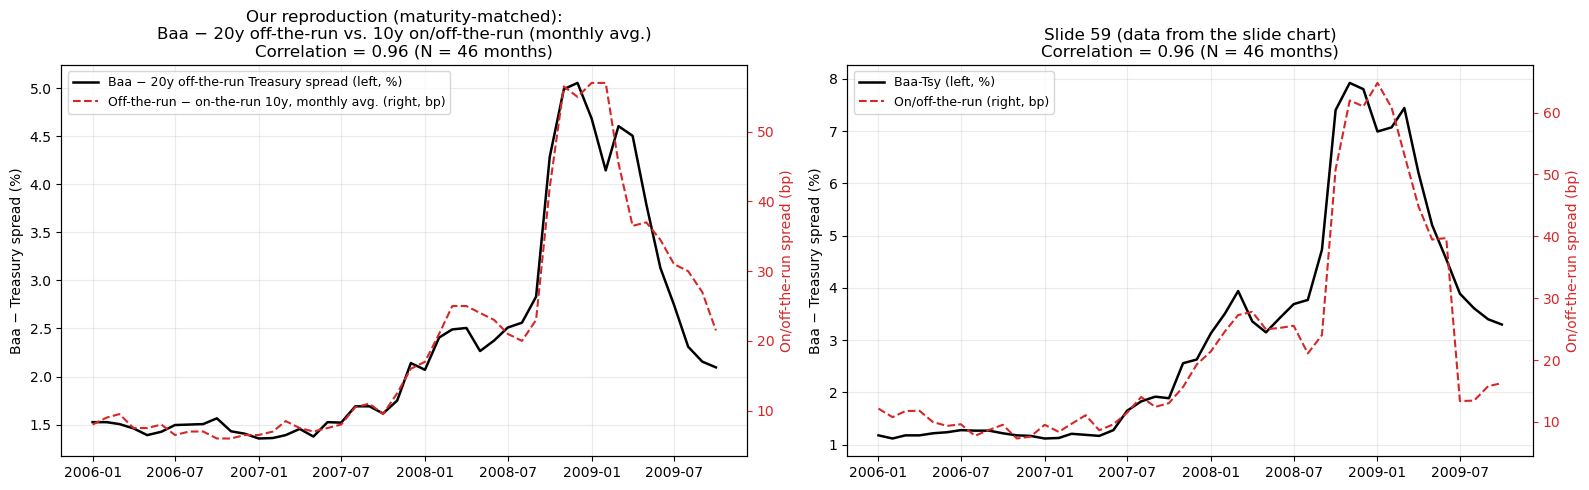

Slide window 2006-01 to 2009-10:
  Ours (Baa - 20y off-the-run vs. monthly-avg. liquidity): corr = 0.964 (N = 46)
  Slide 59: 0.96 (recomputed from the slide data: 0.956)


In [36]:
# Slide 59 data: read from the chart embedded in Ch_9_Bonds.pptx (series "Baa-Tsy (LH axis)" and
# "On-the-run/Off-the-run (RH axis)"), monthly, Jan 2006 - Oct 2009.
SLIDE_BAA_TSY = [1.18, 1.12, 1.18, 1.18, 1.22, 1.24, 1.28, 1.27, 1.27, 1.22, 1.18, 1.17, 1.12, 1.13, 1.21, 1.19,
                 1.17, 1.28, 1.65, 1.83, 1.92, 1.89, 2.56, 2.63, 3.13, 3.51, 3.94, 3.36, 3.15, 3.43, 3.69, 3.77,
                 4.73, 7.40, 7.92, 7.80, 6.99, 7.07, 7.44, 6.20, 5.20, 4.55, 3.89, 3.61, 3.40, 3.30]
SLIDE_LIQ = [12.145, 10.761, 11.742, 11.798, 9.951, 9.353, 9.613, 7.746, 8.694, 9.528, 7.311, 7.609, 9.523, 8.379,
             9.681, 11.074, 8.643, 9.601, 11.467, 14.023, 12.423, 13.029, 15.636, 19.272, 21.382, 24.634, 27.270,
             27.783, 24.964, 25.192, 25.536, 21.065, 24.035, 50.804, 61.951, 60.998, 64.794, 60.796, 53.189, 44.833,
             39.474, 39.711, 13.365, 13.433, 15.765, 16.265]
slide = pd.DataFrame({'slide_spread': SLIDE_BAA_TSY, 'slide_liq': SLIDE_LIQ},
                     index=pd.period_range(SLIDE_START, SLIDE_END, freq='M'))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
dual_axis_plot(series['spread'], series['liq'], 'Our reproduction (maturity-matched):\nBaa − 20y off-the-run vs. 10y on/off-the-run (monthly avg.)',
               SLIDE_START, SLIDE_END, recessions=False, ax=axes[0])
ax, ax2 = axes[1], axes[1].twinx()
ax.plot(slide.index.to_timestamp(), slide['slide_spread'], color='black', lw=1.8)
ax2.plot(slide.index.to_timestamp(), slide['slide_liq'], color='tab:red', ls='--', lw=1.5)
ax.set_ylabel('Baa − Treasury spread (%)'); ax2.set_ylabel('On/off-the-run spread (bp)', color='tab:red')
ax2.tick_params(axis='y', colors='tab:red'); ax.grid(alpha=0.25)
ax.set_title(f'Slide 59 (data from the slide chart)\nCorrelation = {slide.corr().iloc[0, 1]:.2f} (N = {len(slide)} months)')
ax.legend(ax.get_lines() + ax2.get_lines(), ['Baa-Tsy (left, %)', 'On/off-the-run (right, bp)'], loc='upper left', fontsize=9)
fig.tight_layout()
plt.show()

win = lambda x: x.loc[SLIDE_START:SLIDE_END]
rho_base, n_base = corr_n(win(series['spread']), win(series['liq']))
print(f'Slide window {SLIDE_START} to {SLIDE_END}:')
print(f'  Ours (Baa - 20y off-the-run vs. monthly-avg. liquidity): corr = {rho_base:.3f} (N = {n_base})')
print(f'  Slide 59: 0.96 (recomputed from the slide data: {slide.corr().iloc[0, 1]:.3f})')

## 6. Extending to the longest available sample (requirement 6)

The liquidity proxy starts in **February 1986**: the on-the-run file starts in Jan 1986, and one month is used to form the first monthly average. The Treasury files end in **September 2026**. This gives the longest common sample. Grey bands are NBER recessions. The lower panel shows a rolling 36-month correlation, to see *when* the relationship is strong.

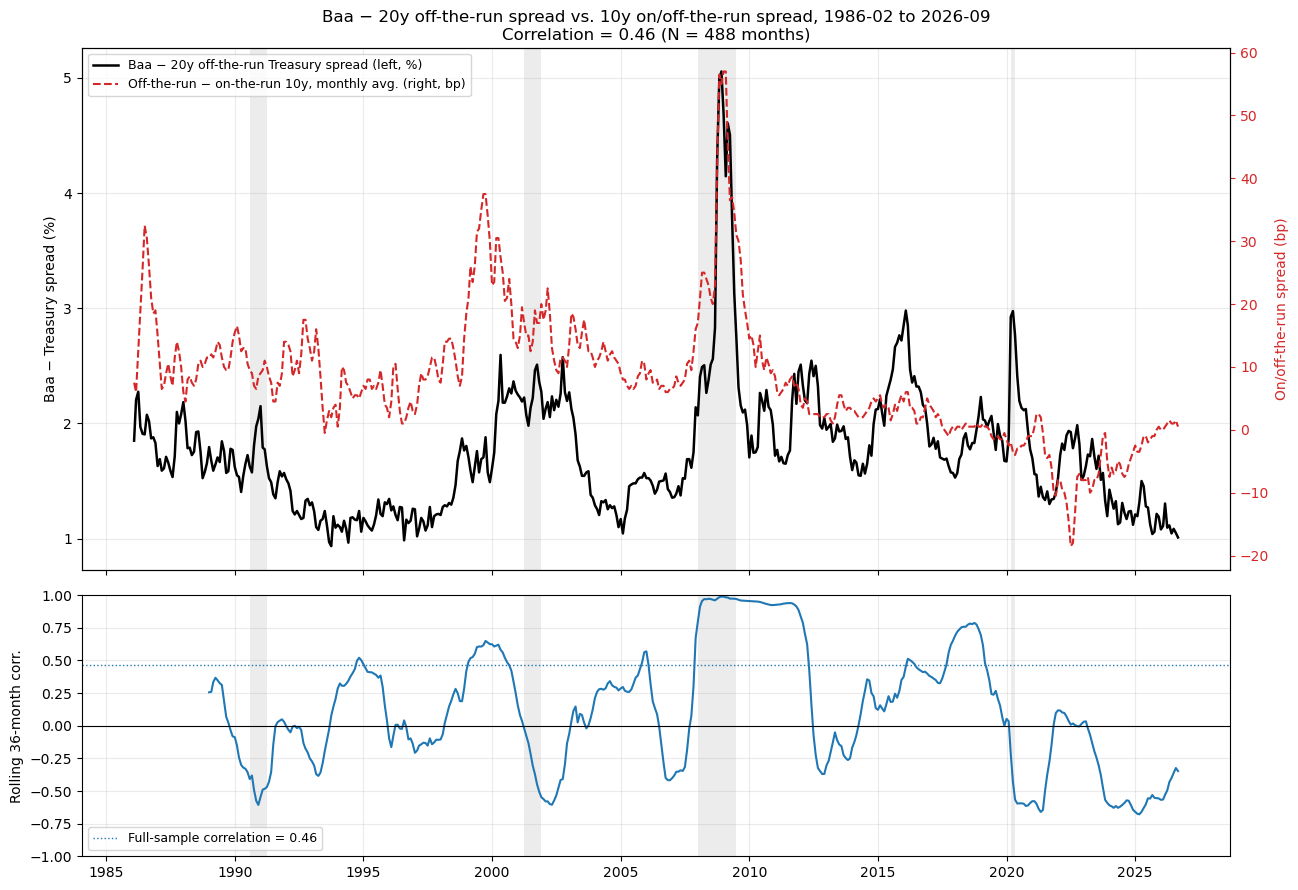

,Correlation,N
Sample,,
Slide window (2006-01 to 2009-10),0.964,46
Full sample (1986-02 to 2026-09),0.462,488
Full sample excluding 2019 onward,0.519,395


Share of months with rolling 36-month correlation above 0.5: 19%


In [37]:
rho_full, n_full = corr_n(analysis['spread'], analysis['liq'])
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
dual_axis_plot(analysis['spread'], analysis['liq'],
               f'Baa − 20y off-the-run spread vs. 10y on/off-the-run spread, {SAMPLE_START} to {SAMPLE_END}', ax=axes[0])
rolling = analysis['spread'].rolling(36, min_periods=36).corr(analysis['liq'])
axes[1].plot(rolling.index.to_timestamp(), rolling, color='tab:blue')
axes[1].axhline(0, color='black', lw=0.8)
axes[1].axhline(rho_full, color='tab:blue', ls=':', lw=1, label=f'Full-sample correlation = {rho_full:.2f}')
shade_recessions(axes[1])
axes[1].set_ylabel('Rolling 36-month corr.')
axes[1].set_ylim(-1, 1)
axes[1].legend(loc='lower left', fontsize=9)
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()

periods = {'Slide window (2006-01 to 2009-10)': (SLIDE_START, SLIDE_END),
           f'Full sample ({SAMPLE_START} to {SAMPLE_END})': (None, None),
           'Full sample excluding 2019 onward': (None, '2018-12')}
display(pd.DataFrame([{'Sample': k, 'Correlation': round(corr_n(analysis['spread'].loc[a:b], analysis['liq'].loc[a:b])[0], 3),
                       'N': corr_n(analysis['spread'].loc[a:b], analysis['liq'].loc[a:b])[1]}
                      for k, (a, b) in periods.items()]).set_index('Sample'))
print('Share of months with rolling 36-month correlation above 0.5:', f'{(rolling > 0.5).mean():.0%}')

## 7. Comparison with slide 59 (requirement 7)

Because we have the slide's own numbers, we can separate the two pieces of the comparison: (a) is *our liquidity proxy* the same as the slide's, and (b) is *our credit spread* the same as the slide's?

,Slide 59,"Ours: baseline (Baa − 20y off-the-run, monthly-avg. liq.)"
Spread: mean (%),3.08,2.33
Spread: 2006 average (%),1.21,1.48
Spread: peak (%),7.92,5.05
Spread: peak month,2008-11,2008-12
Liquidity: mean (bp),22.09,20.21
Liquidity: 2006 average (bp),9.69,7.37
Liquidity: peak (bp),64.79,57.00
Liquidity: peak month,2009-01,2009-01
Correlation spread vs. liquidity,0.96,0.96


How closely do our series track the slide's series (Jan 2006 - Oct 2009)?
  Baa - 20y off-the-run spread   corr with slide = 0.984 | mean gap (slide - ours) = +0.75 pp
  Baa - 30y off-the-run spread   corr with slide = 0.979 | mean gap (slide - ours) = +0.64 pp
  Baa - GS20 spread              corr with slide = 0.985 | mean gap (slide - ours) = +0.73 pp
  liquidity, month-end           corr with slide = 0.945 | mean gap (slide - ours) = +1.77 bp
  liquidity, monthly avg.        corr with slide = 0.953 | mean gap (slide - ours) = +1.89 bp


,"Our liquidity, monthly avg. (baseline)","Our liquidity, month-end",Slide 59 liquidity,Spread 2006 avg. (%),Spread peak (%)
"Baa − 20y off-the-run (baseline, matched)",0.964,0.955,0.968,1.478,5.055
Baa − 30y off-the-run (matched),0.961,0.955,0.972,1.633,5.290
Baa − GS20 (matched),0.961,0.955,0.967,1.487,5.250
Baa − 3m T-bill,0.942,0.926,0.866,1.753,9.020
Slide 59 spread,0.972,0.969,0.956,1.209,7.920


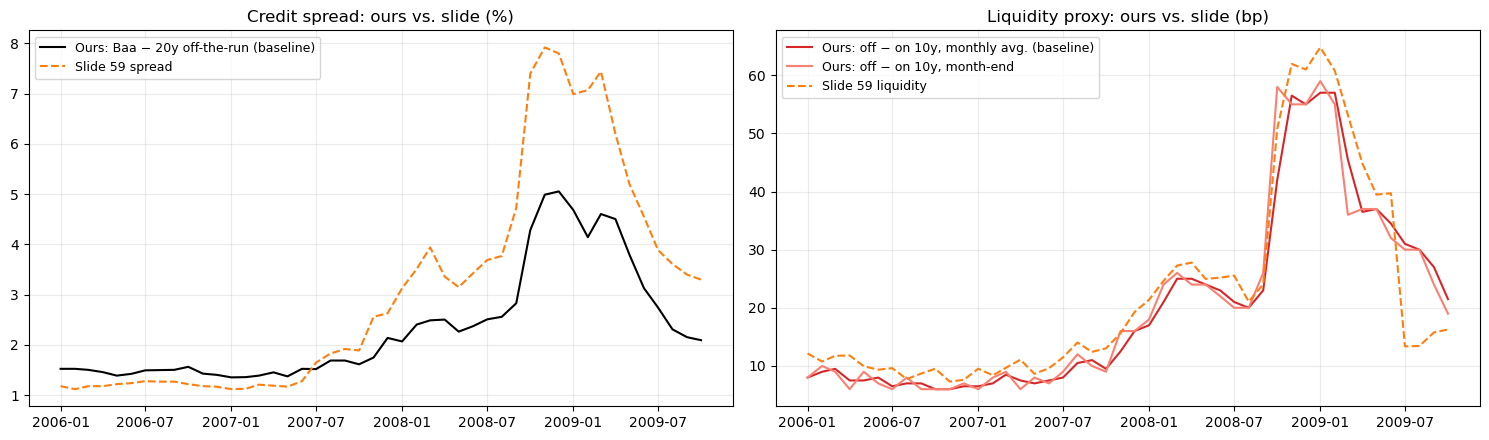

In [38]:
w = series.loc[SLIDE_START:SLIDE_END].join(slide)
def describe_pair(sp, lq):
    return [w[sp].mean(), w[sp].iloc[:12].mean(), w[sp].max(), str(w[sp].idxmax()),
            w[lq].mean(), w[lq].iloc[:12].mean(), w[lq].max(), str(w[lq].idxmax()), w[sp].corr(w[lq])]
comparison = pd.DataFrame({
    'Slide 59': describe_pair('slide_spread', 'slide_liq'),
    'Ours: baseline (Baa − 20y off-the-run, monthly-avg. liq.)': describe_pair('spread', 'liq'),
}, index=['Spread: mean (%)', 'Spread: 2006 average (%)', 'Spread: peak (%)', 'Spread: peak month',
          'Liquidity: mean (bp)', 'Liquidity: 2006 average (bp)', 'Liquidity: peak (bp)', 'Liquidity: peak month',
          'Correlation spread vs. liquidity'])
fmt2 = lambda v: f'{v:.2f}' if isinstance(v, float) else v
display(comparison.map(fmt2) if hasattr(comparison, 'map') else comparison.applymap(fmt2))

print("How closely do our series track the slide's series (Jan 2006 - Oct 2009)?")
for label, col, ref in [('Baa - 20y off-the-run spread', 'spread', 'slide_spread'), ('Baa - 30y off-the-run spread', 'spread_30y', 'slide_spread'),
                        ('Baa - GS20 spread', 'spread_gs20', 'slide_spread'),
                        ('liquidity, month-end', 'liq_me', 'slide_liq'), ('liquidity, monthly avg.', 'liq', 'slide_liq')]:
    unit = 'pp' if 'spread' in col else 'bp'
    print(f'  {label:30s} corr with slide = {w[col].corr(w[ref]):.3f} | mean gap (slide - ours) = {(w[ref] - w[col]).mean():+.2f} {unit}')

spread_variants = [('Baa − 20y off-the-run (baseline, matched)', 'spread'), ('Baa − 30y off-the-run (matched)', 'spread_30y'),
                   ('Baa − GS20 (matched)', 'spread_gs20'),
                   ('Baa − 3m T-bill', 'spread_3m'), ('Slide 59 spread', 'slide_spread')]
liq_variants = [('Our liquidity, monthly avg. (baseline)', 'liq'), ('Our liquidity, month-end', 'liq_me'), ('Slide 59 liquidity', 'slide_liq')]
variant_table = pd.DataFrame({l_label: [corr_n(w[s_col], w[l_col])[0] for _, s_col in spread_variants] for l_label, l_col in liq_variants},
                             index=[lab for lab, _ in spread_variants])
variant_table['Spread 2006 avg. (%)'] = [w[c].iloc[:12].mean() for _, c in spread_variants]
variant_table['Spread peak (%)'] = [w[c].max() for _, c in spread_variants]
display(variant_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(w.index.to_timestamp(), w['spread'], color='black', label='Ours: Baa − 20y off-the-run (baseline)')
axes[0].plot(w.index.to_timestamp(), w['slide_spread'], color='tab:orange', ls='--', label='Slide 59 spread')
axes[0].set_title('Credit spread: ours vs. slide (%)'); axes[0].legend(fontsize=9); axes[0].grid(alpha=0.25)
axes[1].plot(w.index.to_timestamp(), w['liq'], color='tab:red', label='Ours: off − on 10y, monthly avg. (baseline)')
axes[1].plot(w.index.to_timestamp(), w['liq_me'], color='salmon', label='Ours: off − on 10y, month-end')
axes[1].plot(w.index.to_timestamp(), w['slide_liq'], color='tab:orange', ls='--', label='Slide 59 liquidity')
axes[1].set_title('Liquidity proxy: ours vs. slide (bp)'); axes[1].legend(fontsize=9); axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()

### What the comparison shows

**The correlation replicates.** Over the slide's 46 months (Jan 2006 – Oct 2009), our maturity-matched series give **0.96** (0.964). Recomputing from the slide's own chart data gives 0.956, so this is the slide's number. Every spread and proxy combination we tried gives 0.93–0.97 in this window, so the headline number does not depend on the maturity choice. The shape also matches: both series are flat from 2006 to mid-2007, rise in two steps (Aug 2007, then the Mar 2008 Bear Stearns episode), peak after the Lehman failure, and fall through 2009.

**Our liquidity proxy is essentially the slide's.** It correlates **0.95** with the slide's proxy and is only about 2 bp lower on average. Both peak in **Jan 2009** (57 bp vs. 65 bp). The one visible difference is mid-2009, when the slide's proxy drops from about 40 bp to 13 bp in a single month while ours declines gradually. That points to a construction difference, such as a differently fitted off-the-run curve or the timing of a new 10-year auction, rather than a different concept.

**The credit spread differs in level, not in shape.** Our matched spreads correlate about 0.98 with the slide's spread, but none reproduces its levels. The slide is lower in calm 2006 (1.21%) than our baseline (1.48%), yet much higher at the peak (7.92% vs. 5.05%). No Treasury benchmark can produce both. Matched spreads peak at 5.1–5.3%, while the T-bill version peaks at 9.0% and also starts too high (1.75%). The most likely explanation is that the slide uses a **different corporate bond index**, for example a BBB index spread over duration-matched Treasuries, which is lower in calm markets and spikes more in crises than Moody's seasoned Baa average. We cannot confirm the slide's source. Slide 55's 2.09% average Baa spread for 1987–2011 is also higher than our matched 1.72%, which again suggests a different index (or a shorter-maturity Treasury benchmark).

**Explanations for the differences, in order of importance:**
1. **Corporate index construction.** It changes the *level* and *amplitude* of the spread but hardly its timing, which is why the correlation is unaffected.
2. **Treasury maturity.** It changes the *level* of the spread: matched spreads peak at 5.1–5.3%, while the T-bill spread peaks at 9.0%, because Fed rate cuts in 2008 add term-spread movements to it. It barely changes the correlation (0.94–0.96).
3. **Liquidity proxy construction and timing.** Month-end vs. monthly-average values, and the choice of fitted off-the-run curve, explain the mid-2009 gap and the few-bp level difference.
4. **Sample period.** It is identical by construction: exactly the slide's 46 months.

Note on the slide text: "both rose from about 1% to about 8%" describes the *spread* (left axis, %). The liquidity proxy (right axis) rose from about 10 bp to about 65 bp.

### Extended sample (requirement 6): the 0.96 does not generalize

Over the full Feb 1986 – Sep 2026 sample, the correlation falls to **0.46** (N = 488), or 0.52 if we stop before 2019, when the proxy turns negative. The rolling 36-month correlation in §6 is above 0.5 only about a fifth of the time, and it is near 1 only in the 2007–2012 window. Around the **1990–91, 2001 and 2020 recessions** it is *negative*: credit spreads widened while the on/off-the-run spread did not. In March 2020, for example, the Fed's very large and fast Treasury purchases restored Treasury-market liquidity within weeks, yet credit spreads still jumped. The proxy also has its own non-credit episodes, such as the 1998–2000 spike, a period of LTCM-related flight to liquidity and Treasury debt buybacks that made on-the-run bonds scarce. **The slide's near-perfect co-movement is a property of the 2008 crisis, not a stable feature of credit markets.**

## 8. Liquidity vs. default risk (requirement 8)

In the Merton model, bondholders are short a put on the firm's assets, so spreads widen when asset volatility rises (slides 48–51). We use **VIX as the default-risk proxy** and the on/off-the-run spread as the **liquidity proxy**, and estimate:

1. Spread = a + b · Liquidity
2. Spread = a + c · VIX
3. Spread = a + b · Liquidity + c · VIX

The dependent variable is the maturity-matched Baa − 20y off-the-run spread. All three use the **same sample, Jan 1990 – Sep 2026**, because VIX starts in 1990. This keeps the R² values comparable. t-statistics are Newey-West with 12 lags (one year), because the series are highly persistent. To compare the size of the two effects, we also report **standardized coefficients**: the change in the spread, in percentage points, for a one-standard-deviation move in each regressor.

,(1) Liquidity,(2) VIX,(3) Both
Liquidity (per bp),0.0261,,0.0123
Liquidity (per bp): t-stat,(2.12),,(1.82)
VIX (per point),,0.0512,0.0431
VIX (per point): t-stat,,(4.11),(5.80)
Constant,1.5486,0.7524,0.8159
Constant: t-stat,(15.25),(3.26),(4.62)
Liquidity: +1 SD effect (pp),0.275,,0.130
VIX: +1 SD effect (pp),,0.377,0.317
R²,0.219,0.410,0.448
N (months),441,441,441


Dependent variable: Baa − 20y off-the-run spread (pp). Newey-West t-stats with 12 lags in parentheses.
Incremental R² from adding liquidity to VIX: 0.038; from adding VIX to liquidity: 0.229
Correlation between the two regressors (liquidity, VIX): 0.46


,"corr(Baa − Tsy, VIX)",N
Sample,,
Slide 51 (1986–2013),0.640,≈ 330
1990–2013 (closest to slide 51; VIX starts 1990),0.754,288
1990-01 to 2026-09 (full),0.640,441


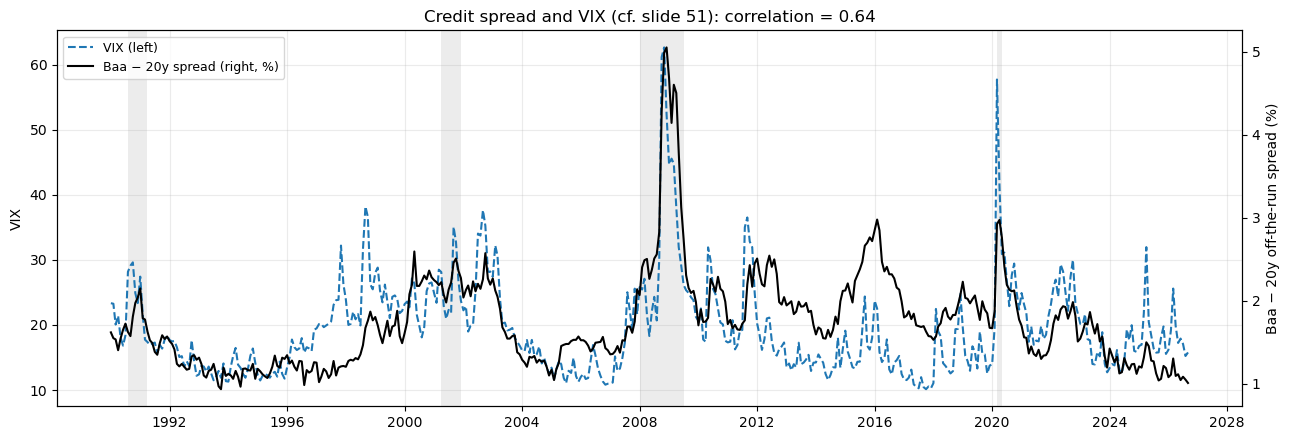

In [39]:
NW_LAGS = 12
reg = analysis[['spread', 'liq', 'VIX']].dropna()
specs = {'(1) Liquidity': ['liq'], '(2) VIX': ['VIX'], '(3) Both': ['liq', 'VIX']}
fits = {name: ols_hac(reg['spread'], reg[cols], lags=NW_LAGS) for name, cols in specs.items()}

def regression_table(fits, sd):
    rows = {}
    for name, f in fits.items():
        col = {}
        for var, label in [('liq', 'Liquidity (per bp)'), ('VIX', 'VIX (per point)'), ('const', 'Constant')]:
            if var in f['coef']:
                col[label] = f"{f['coef'][var]:.4f}"
                col[f'{label}: t-stat'] = f"({f['t'][var]:.2f})"
        for var, label in [('liq', 'Liquidity: +1 SD effect (pp)'), ('VIX', 'VIX: +1 SD effect (pp)')]:
            if var in f['coef']:
                col[label] = f"{f['coef'][var] * sd[var]:.3f}"
        col['R²'] = f"{f['r2']:.3f}"
        col['N (months)'] = f"{f['n']}"
        col['Sample'] = f"{f['start']} to {f['end']}"
        rows[name] = col
    order = ['Liquidity (per bp)', 'Liquidity (per bp): t-stat', 'VIX (per point)', 'VIX (per point): t-stat', 'Constant',
             'Constant: t-stat', 'Liquidity: +1 SD effect (pp)', 'VIX: +1 SD effect (pp)', 'R²', 'N (months)', 'Sample']
    return pd.DataFrame(rows).reindex(order).fillna('')

sd = reg[['liq', 'VIX']].std()
regression_results = regression_table(fits, sd)
display(regression_results)
print(f'Dependent variable: Baa − 20y off-the-run spread (pp). Newey-West t-stats with {NW_LAGS} lags in parentheses.')
print(f"Incremental R² from adding liquidity to VIX: {fits['(3) Both']['r2'] - fits['(2) VIX']['r2']:.3f}; "
      f"from adding VIX to liquidity: {fits['(3) Both']['r2'] - fits['(1) Liquidity']['r2']:.3f}")
print(f"Correlation between the two regressors (liquidity, VIX): {reg['liq'].corr(reg['VIX']):.2f}")

vix_corr = pd.DataFrame([
    {'Sample': 'Slide 51 (1986–2013)', 'corr(Baa − Tsy, VIX)': 0.64, 'N': '≈ 330'},
    {'Sample': '1990–2013 (closest to slide 51; VIX starts 1990)', 'corr(Baa − Tsy, VIX)': round(corr_n(reg['spread'].loc[:'2013-12'], reg['VIX'].loc[:'2013-12'])[0], 3), 'N': corr_n(reg['spread'].loc[:'2013-12'], reg['VIX'].loc[:'2013-12'])[1]},
    {'Sample': f'{reg.index.min()} to {reg.index.max()} (full)', 'corr(Baa − Tsy, VIX)': round(corr_n(reg['spread'], reg['VIX'])[0], 3), 'N': len(reg)},
]).set_index('Sample')
display(vix_corr)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(reg.index.to_timestamp(), reg['VIX'], color='tab:blue', ls='--', label='VIX (left)')
ax.set_ylabel('VIX')
ax2 = ax.twinx()
ax2.plot(reg.index.to_timestamp(), reg['spread'], color='black', label='Baa − 20y spread (right, %)')
ax2.set_ylabel('Baa − 20y off-the-run spread (%)')
shade_recessions(ax)
ax.set_title(f"Credit spread and VIX (cf. slide 51): correlation = {reg['spread'].corr(reg['VIX']):.2f}")
ax.legend(ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0],
          ['VIX (left)', 'Baa − 20y spread (right, %)'], loc='upper left', fontsize=9)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### What the regressions show

**On their own, both factors are related to the spread, but VIX explains almost twice as much.**
- **Liquidity alone:** b = 0.026 (t = 2.12), R² = **0.22**. A 1 bp wider on/off-the-run spread goes with a 2.6 bp wider Baa spread. A one-standard-deviation move (about 10 bp) adds about 0.28 pp.
- **VIX alone:** c = 0.051 (t = 4.11), R² = **0.41**. A 10-point rise in VIX goes with a 0.51 pp wider spread. A one-SD move adds about 0.38 pp.

**Together (column 3), VIX dominates and liquidity is no longer significant at 5%.** The liquidity coefficient halves (0.026 → 0.012, t = 1.82), while VIX barely moves (0.051 → 0.043, t = 5.80). Adding liquidity to VIX raises R² by only **0.04** (0.41 → 0.45). Adding VIX to liquidity raises it by **0.23**. Much of what liquidity "explains" on its own is shared with VIX: the two proxies have a correlation of 0.46, because both spike in crises.

**Why the benchmark matters.** We measure the spread against the *off-the-run* curve, so the on-the-run liquidity premium is not mechanically part of the spread (§3). A benchmark built from on-the-run bonds would put part of the liquidity proxy inside the dependent variable and overstate liquidity's role. Our liquidity estimates are therefore conservative.

**Link to the structural (Merton) model.** The model predicts that spreads widen when asset volatility rises, because bondholders are short a put on the firm's assets. The VIX coefficient is positive and highly significant in every specification, as predicted. Our spread–VIX correlation is **0.64** over 1990–2026, exactly the slide 51 value of **0.64** (1986–2013). Over 1990–2013, the sample closest to the slide's, it is 0.75. Slide 51 probably starts in 1986 using the older VXO index, since VIX begins in 1990.

**Link to the credit spread puzzle (slide 54).** Even with both proxies, **55% of the variation in the spread is unexplained** (R² = 0.45). In monthly changes (§10), VIX explains 22% and adding liquidity raises this only to 25%. This matches Collin-Dufresne, Goldstein & Martin: default-risk variables explain about a quarter of spread changes, and most of the rest is a common factor unrelated to measured default risk. Our Treasury liquidity proxy captures only a small slice of that common factor *on average*. §10 shows it captures much more *in a crisis*.

**Caveat.** These are level regressions of persistent series, so the R² values partly reflect shared slow-moving trends. The change regressions in §10 are the stricter test and give the same ranking: VIX first, liquidity a distant second outside the crisis.

## 9. Credit spread puzzle decomposition (requirement 9)

Following slides 55–58, we compute **expected default loss = default probability × (1 − recovery rate)**.

- **Baseline (slide 55):** Moody's Baa annual credit loss rate, 1982–2008 = **0.124%** a year. This is already PD × (1 − R). Slide 56 gives an average recovery of **41%**, which implies a Baa default probability of 0.124 / (1 − 0.41) ≈ **0.21%** a year.
- **Conservative upper bound (slide 57):** 150-year average across *all* US corporate bonds, 1.5% default × 50% loss = **0.75%** a year. This overstates Baa losses, because it includes junk bonds and the 1870s and 1930s default waves. It shows how robust the puzzle is.

The **residual** = average (maturity-matched) spread − expected loss is the part not explained by expected defaults. To see how much of it is liquidity, we use the joint regression (3): liquidity component = b × average liquidity proxy, where a proxy value of zero means no Treasury liquidity premium. The VIX component (c × average VIX) is shown alongside. We do this for the full regression sample, the crisis, and normal times.

Expected loss (baseline) = PD 0.210% x (1 - 41%) = 0.124% per year
Expected loss (upper bound, all corporates 1866-2008) = 1.5% x (1 - 50%) = 0.750% per year


,Full (1990-01 to 2026-09),Crisis (2007-08 to 2009-06),Normal times (excl. crisis)
Average Baa − 20y spread (pp),1.75,3.05,1.68
"Expected default loss, slide 55 (pp)",0.12,0.12,0.12
Spread ÷ expected loss (×),14.1×,24.6×,13.5×
Residual after expected loss (pp),1.62,2.92,1.55
Average liquidity proxy (bp),7.62,29.54,6.41
"Liquidity component b·LIQ, joint reg. (pp)",0.09,0.36,0.08
share of residual,6%,12%,5%
"Liquidity component, liquidity-only reg. (pp)",0.20,0.77,0.17
share of residual,12%,26%,11%
VIX component c·VIX (pp),0.84,1.39,0.81


Average Baa − 20y off-the-run spread 1987-2011: 1.72% (slide 55: 2.09%)


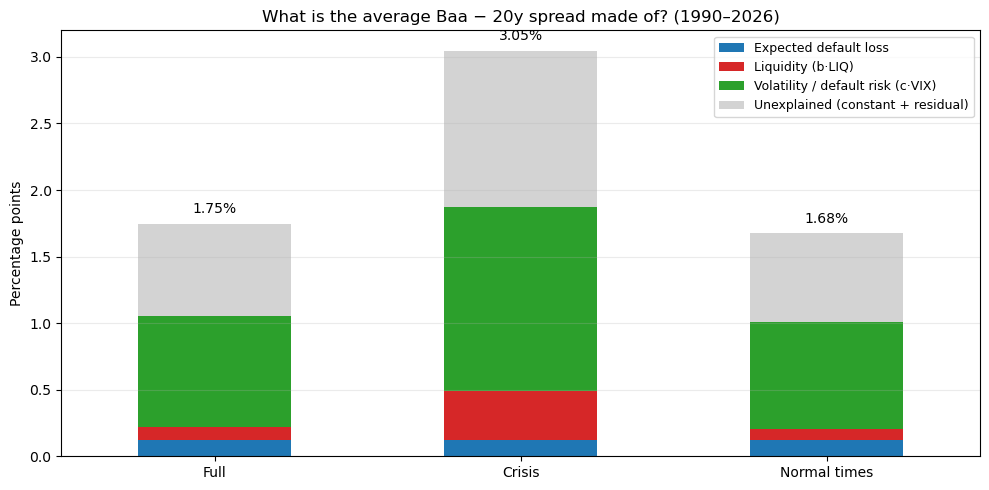

In [40]:
EL_BASE = 0.124                 # % per year, slide 55 (Baa loss rate, Moody's 1982-2008)
RECOVERY = 0.41                 # slide 56 average recovery rate
PD_IMPLIED = EL_BASE / (1 - RECOVERY)
EL_UPPER = 1.5 * (1 - 0.50)     # slide 57: 1.5% default rate x 50% loss given default = 0.75%
print(f'Expected loss (baseline) = PD {PD_IMPLIED:.3f}% x (1 - {RECOVERY:.0%}) = {EL_BASE:.3f}% per year')
print(f'Expected loss (upper bound, all corporates 1866-2008) = 1.5% x (1 - 50%) = {EL_UPPER:.3f}% per year')

b_liq, c_vix, a0 = fits['(3) Both']['coef']['liq'], fits['(3) Both']['coef']['VIX'], fits['(3) Both']['coef']['const']
b_liq_alone = fits['(1) Liquidity']['coef']['liq']
gfc = in_periods(reg.index, [(GFC_START, GFC_END)])
windows = {f'Full ({reg.index.min()} to {reg.index.max()})': reg,
           f'Crisis ({GFC_START} to {GFC_END})': reg[gfc],
           'Normal times (excl. crisis)': reg[~gfc]}
puzzle = {}
for name, d in windows.items():
    avg_spread, avg_liq, avg_vix = d['spread'].mean(), d['liq'].mean(), d['VIX'].mean()
    resid = avg_spread - EL_BASE
    liq_comp, vix_comp = b_liq * avg_liq, c_vix * avg_vix
    puzzle[name] = {
        'Average Baa − 20y spread (pp)': avg_spread,
        'Expected default loss, slide 55 (pp)': EL_BASE,
        'Spread ÷ expected loss (×)': avg_spread / EL_BASE,
        'Residual after expected loss (pp)': resid,
        'Average liquidity proxy (bp)': avg_liq,
        'Liquidity component b·LIQ, joint reg. (pp)': liq_comp,
        '  share of residual': liq_comp / resid,
        'Liquidity component, liquidity-only reg. (pp)': b_liq_alone * avg_liq,
        '  share of residual ': b_liq_alone * avg_liq / resid,
        'VIX component c·VIX (pp)': vix_comp,
        '  share of residual  ': vix_comp / resid,
        'Unexplained after EL, liquidity, VIX (pp)': resid - liq_comp - vix_comp,
        'Residual using 0.75% upper-bound EL (pp)': avg_spread - EL_UPPER,
        'Months': len(d),
    }
puzzle_table = pd.DataFrame(puzzle)
fmt = puzzle_table.copy().astype(object)
for idx in puzzle_table.index:
    for c in puzzle_table.columns:
        v = puzzle_table.loc[idx, c]
        fmt.loc[idx, c] = (f'{v:.0f}' if idx == 'Months' else f'{v:.1f}×' if '×' in idx
                           else f'{v:.0%}' if 'share' in idx else f'{v:.2f}')
display(fmt)

# Long-run comparison with slide 55's average Baa spread (1987-2011 = 2.09%)
print(f"Average Baa − 20y off-the-run spread 1987-2011: {analysis['spread'].loc['1987-01':'2011-12'].mean():.2f}% (slide 55: 2.09%)")

# Stacked bar of the average decomposition (cf. slide 58)
parts = pd.DataFrame({
    'Expected default loss': [EL_BASE] * 3,
    'Liquidity (b·LIQ)': [puzzle[k]['Liquidity component b·LIQ, joint reg. (pp)'] for k in windows],
    'Volatility / default risk (c·VIX)': [puzzle[k]['VIX component c·VIX (pp)'] for k in windows],
    'Unexplained (constant + residual)': [puzzle[k]['Unexplained after EL, liquidity, VIX (pp)'] for k in windows],
}, index=[k.split(' (')[0] for k in windows])
ax = parts.plot(kind='bar', stacked=True, figsize=(10, 5), color=['tab:blue', 'tab:red', 'tab:green', 'lightgrey'], rot=0)
for i, k in enumerate(windows):
    ax.text(i, puzzle[k]['Average Baa − 20y spread (pp)'] + 0.08, f"{puzzle[k]['Average Baa − 20y spread (pp)']:.2f}%", ha='center')
ax.set_ylabel('Percentage points')
ax.set_title('What is the average Baa − 20y spread made of? (1990–2026)')
ax.legend(loc='upper right', fontsize=9)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

### What the decomposition shows

**The puzzle is clearly present.** The average maturity-matched Baa spread over 1990–2026 is **1.75%**, about **14×** the 0.124% expected default loss. Slide 55 reports about 17×, using a 2.09% average Baa spread for 1987–2011. Our matched spread averages 1.72% over the same window, lower because of the maturity-matched benchmark and a different index. Expected losses account for only about **7%** of the matched spread, leaving about **1.62 pp**. Even with the deliberately pessimistic 0.75% expected loss (all US corporate bonds, 1866–2008), 1.00 pp remains. The puzzle does not depend on which loss rate we use.

**How much of the residual can Treasury liquidity account for?**
- **On average, little.** About 0.09 pp, or **6%** of the residual, using the joint regression. The liquidity-only regression gives an upper bound of 0.20 pp (12%), which also credits liquidity with what it shares with VIX.
- **In the crisis, much more.** The average liquidity proxy rises from about 6 bp in normal times to **30 bp** in Aug 2007 – Jun 2009, and the liquidity component rises more than fourfold, to 0.36 pp (**12%** of the residual), or 0.77 pp (26%) on the upper-bound measure. At the January 2009 peak (57 bp), it is about 0.7–1.5 pp on its own.
- **The VIX component** (c × average VIX ≈ 0.84 pp, about half of the residual) is best read as the **default risk premium**: compensation for the fact that defaults and losses concentrate in high-volatility bad times (slides 56–57). It is not expected loss.
- **About 0.7 pp stays unexplained** (the regression constant plus the residual). This is what slide 55 attributes to taxes, embedded call options and *corporate-bond-specific* illiquidity.

**Interpretation.** Our liquidity share is best read as a **lower bound** on liquidity's role. The on/off-the-run spread measures *Treasury-market* liquidity stress, not how hard it is to trade an individual corporate bond. Corporate bond illiquidity is persistent and probably sits largely in the unexplained part. The pattern still matches slide 58: expected losses are a thin slice of the spread in every period, and the liquidity slice grows sharply in a crisis.

**Caveats.**
1. The 0.124% loss rate is a 1982–2008 average. In recessions, defaults rise and recoveries fall to 20–25% (slide 56), so expected losses in the crisis column are higher than shown.
2. The crisis column rests on only 23 months.
3. The b·LIQ and c·VIX components come from a linear regression in levels and treat a proxy value of zero as "no premium".
4. Off-the-run Treasury yields themselves carry a small illiquidity premium and a "safety" premium relative to a true risk-free rate, so the spread is measured against an imperfect benchmark.

## 10. Sensitivity analysis (requirement 10)

We change **one assumption at a time** and recompute the correlation between the credit spread and the liquidity proxy. As the default-risk benchmark, each row also compares the spread–liquidity and spread–VIX correlations on the *same* months (1990 onward, because VIX starts in 1990). The assumptions tested:

| Group | Baseline | Alternatives |
|---|---|---|
| A. Sample period | 1986-02 to 2026-09 | Slide window; before, during and after the crisis; excluding the crisis; NBER recessions vs. expansions; before 2019 |
| B. Levels vs. changes | Levels | Monthly changes (full, excluding crisis, post-crisis); 12-month changes |
| C. Treasury benchmark | 20y off-the-run (matched) | 30y off-the-run (matched); FRED GS20 (matched, gap months dropped); 3-month T-bill (mismatched diagnostic) |
| D. Liquidity proxy | 10y off − on, monthly average | 10y month-end value; 5y off − on; 2y off − on |
| E. Frequency / timing | Monthly averages | Quarterly averages; month-end VIX and liquidity |
| F. Winsorization | None | 1%/99% on both series |

In [41]:
def sens_row(group, label, spread, liq, vix):
    rho_l, n_l = corr_n(spread, liq)
    common = pd.concat([spread, liq, vix], axis=1).dropna()          # same months for the liquidity-vs-VIX comparison
    c = common.corr().to_numpy() if len(common) > 2 else np.full((3, 3), np.nan)
    return {'Group': group, 'Assumption': label, 'corr(spread, liquidity)': rho_l, 'N': n_l,
            'corr(spread, liq.), VIX months': c[0, 1], 'corr(spread, VIX), VIX months': c[0, 2], 'N (VIX months)': len(common)}

A = analysis
rec = in_periods(A.index, NBER_RECESSIONS)
crisis = in_periods(A.index, [(GFC_START, GFC_END)])
rows = [sens_row('Baseline', f'Levels, Baa − 20y off-the-run, 10y on/off monthly avg., {SAMPLE_START}–{SAMPLE_END}', A['spread'], A['liq'], A['VIX'])]
# A. sample periods
for label, mask in [('Slide window 2006-01 – 2009-10', (A.index >= pd.Period(SLIDE_START, 'M')) & (A.index <= pd.Period(SLIDE_END, 'M'))),
                    (f'Pre-crisis {SAMPLE_START} – 2007-07', A.index < pd.Period(GFC_START, 'M')),
                    ('Crisis 2007-08 – 2009-06', crisis.to_numpy()),
                    ('Post-crisis 2009-07 – 2026-09', A.index > pd.Period(GFC_END, 'M')),
                    ('Full sample excluding crisis', ~crisis.to_numpy()),
                    ('NBER recession months only', rec.to_numpy()),
                    ('NBER expansion months only', ~rec.to_numpy()),
                    ('Before 2019 (proxy mostly positive)', A.index < pd.Period('2019-01', 'M'))]:
    d = A[mask]
    rows.append(sens_row('A. Sample', label, d['spread'], d['liq'], d['VIX']))
# B. levels vs changes
rows.append(sens_row('B. Transformation', 'Monthly changes (Δ)', A['spread'].diff(), A['liq'].diff(), A['VIX'].diff()))
rows.append(sens_row('B. Transformation', '12-month changes', A['spread'].diff(12), A['liq'].diff(12), A['VIX'].diff(12)))
rows.append(sens_row('B. Transformation', 'Monthly changes, excluding crisis', A['spread'].diff()[~crisis], A['liq'].diff()[~crisis], A['VIX'].diff()[~crisis]))
post = A.index > pd.Period(GFC_END, 'M')
rows.append(sens_row('B. Transformation', 'Monthly changes, post-crisis 2009-07 – 2026-09', A['spread'].diff()[post], A['liq'].diff()[post], A['VIX'].diff()[post]))
# C. Treasury benchmark
rows.append(sens_row('C. Treasury benchmark', 'Baa − 30y off-the-run (matched)', A['spread_30y'], A['liq'], A['VIX']))
rows.append(sens_row('C. Treasury benchmark', 'Baa − GS20 (matched; 1987–93 gap dropped, not filled)', A['spread_gs20'], A['liq'], A['VIX']))
rows.append(sens_row('C. Treasury benchmark', 'Baa − 3m T-bill (mismatched)', A['spread_3m'], A['liq'], A['VIX']))
# D. liquidity proxy
rows.append(sens_row('D. Liquidity proxy', '10y off − on, month-end value', A['spread'], A['liq_me'], A['VIX']))
rows.append(sens_row('D. Liquidity proxy', '5y off − on', A['spread'], A['liq_5y'], A['VIX']))
rows.append(sens_row('D. Liquidity proxy', '2y off − on', A['spread'], A['liq_2y'], A['VIX']))
# E. frequency / timing
q = A[['spread', 'liq', 'VIX']].groupby(A.index.asfreq('Q')).mean()
rows.append(sens_row('E. Frequency / timing', 'Quarterly averages', q['spread'], q['liq'], q['VIX']))
rows.append(sens_row('E. Frequency / timing', 'Month-end VIX and month-end liquidity', A['spread'], A['liq_me'], A['VIX_end']))
# F. winsorization
def winsorize(s, lo=0.01, hi=0.99):
    a, b = s.quantile([lo, hi])
    return s.clip(a, b), int(((s < a) | (s > b)).sum())
ws, n_ws = winsorize(A['spread']); wl, n_wl = winsorize(A['liq']); wv, n_wv = winsorize(A['VIX'].dropna())
rows.append(sens_row('F. Winsorization', f'1%/99% (clips {n_ws} spread, {n_wl} liquidity, {n_wv} VIX obs.)', ws, wl, wv))

sensitivity = pd.DataFrame(rows)
baseline_rho = sensitivity.loc[0, 'corr(spread, liquidity)']
sensitivity['Δ vs. baseline'] = sensitivity['corr(spread, liquidity)'] - baseline_rho
sensitivity['Liquidity beats VIX?'] = np.where(sensitivity['corr(spread, VIX), VIX months'].isna(), 'n/a',
                                               np.where(sensitivity['corr(spread, liq.), VIX months'] > sensitivity['corr(spread, VIX), VIX months'], 'Yes', 'No'))
show_tbl = sensitivity.set_index(['Group', 'Assumption'])
display(show_tbl.round(3))

corr(spread, liquidity)    N  corr(spread, liq.), VIX months  \
Group                 Assumption                                                                                                         
Baseline              Levels, Baa − 20y off-the-run, 10y on/off month...                    0.462  488                           0.468   
A. Sample             Slide window 2006-01 – 2009-10                                        0.964   46                           0.964   
                      Pre-crisis 1986-02 – 2007-07                                          0.481  258                           0.517   
                      Crisis 2007-08 – 2009-06                                              0.955   23                           0.955   
                      Post-crisis 2009-07 – 2026-09                                         0.373  207                           0.373   
                      Full sample excluding crisis                                          0.140  465                           0.120   
                      NBER recession months only                                            0.864   36                           0.864   
                      NBER expansion months only                                            0.138  452                           0.113   
                      Before 2019 (proxy mostly positive)                                   0.519  395                           0.530   
B. Transformation     Monthly changes (Δ)                                                   0.256  487                           0.282   
                      12-month changes                                                      0.527  476                           0.544   
                      Monthly changes, excluding crisis                                     0.089  464                           0.098   
                      Monthly changes, post-crisis 2009-07 – 2026-09                        0.151  207                           0.151   
C. Treasury benchmark Baa − 30y off-the-run (matched)                                       0.530  488                           0.541   
                      Baa − GS20 (matched; 1987–93 gap dropped, not f...                    0.518  407                           0.498   
                      Baa − 3m T-bill (mismatched)                                          0.488  488                           0.512   
D. Liquidity proxy    10y off − on, month-end value                                         0.457  488                           0.463   
                      5y off − on                                                          -0.032  488                          -0.094   
                      2y off − on                                                          -0.065  488                          -0.119   
E. Frequency / timing Quarterly averages                                                    0.473  163                           0.477   
                      Month-end VIX and month-end liquidity                                 0.457  488                           0.463   
F. Winsorization      1%/99% (clips 10 spread, 10 liquidity, 10 VIX o...                    0.415  488                           0.420   

                                                                          corr(spread, VIX), VIX months  N (VIX months)  Δ vs. baseline Liquidity beats VIX?  
Group                 Assumption                                                                                                                              
Baseline              Levels, Baa − 20y off-the-run, 10y on/off month...                          0.640             441           0.000                   No  
A. Sample             Slide window 2006-01 – 2009-10                                              0.936              46           0.502                  Yes  
                      Pre-crisis 1986-02 – 2007-07                                                0.675             211      

### Does the answer to the economic question change? Liquidity vs. VIX horse race under alternative assumptions

The correlation table tells us whether the slide's link survives. The question in §1 is about *liquidity vs. default risk*, so we also rerun the joint regression (3) under the alternatives that matter most. Monthly-change regressions use 3 Newey-West lags, because changes are far less persistent than levels.

In [42]:
R = analysis[['spread', 'liq', 'VIX', 'liq_me', 'VIX_end']].dropna()
crisis_R = in_periods(R.index, [(GFC_START, GFC_END)]).to_numpy()
horse = {
    'Baseline (levels, 1990–2026)': (R['spread'], R[['liq', 'VIX']], NW_LAGS),
    'Crisis only (2007-08 – 2009-06)': (R['spread'][crisis_R], R[['liq', 'VIX']][crisis_R], 3),
    'Excluding crisis': (R['spread'][~crisis_R], R[['liq', 'VIX']][~crisis_R], NW_LAGS),
    'Before 2019': (R['spread'].loc[:'2018-12'], R[['liq', 'VIX']].loc[:'2018-12'], NW_LAGS),
    'Monthly changes': (R['spread'].diff(), R[['liq', 'VIX']].diff(), 3),
    'Monthly changes, excl. crisis': (R['spread'].diff()[~crisis_R], R[['liq', 'VIX']].diff()[~crisis_R], 3),
    'Month-end liquidity and VIX': (R['spread'], R[['liq_me', 'VIX_end']].rename(columns={'liq_me': 'liq', 'VIX_end': 'VIX'}), NW_LAGS),
}
hr = []
for name, (y, X, lags) in horse.items():
    f_l = ols_hac(y, X[['liq']], lags); f_v = ols_hac(y, X[['VIX']], lags); f_b = ols_hac(y, X, lags)
    sd_ = pd.concat([y, X], axis=1).dropna()[['liq', 'VIX']].std()
    hr.append({'Specification': name, 'N': f_b['n'],
               'R² liquidity only': f_l['r2'], 'R² VIX only': f_v['r2'], 'R² both': f_b['r2'],
               't(liquidity) in joint': f_b['t']['liq'], 't(VIX) in joint': f_b['t']['VIX'],
               '+1 SD liquidity (pp)': f_b['coef']['liq'] * sd_['liq'], '+1 SD VIX (pp)': f_b['coef']['VIX'] * sd_['VIX']})
horse_race = pd.DataFrame(hr).set_index('Specification')
display(horse_race.round(3))

,N,R² liquidity only,R² VIX only,R² both,t(liquidity) in joint,t(VIX) in joint,+1 SD liquidity (pp),+1 SD VIX (pp)
Specification,,,,,,,,
"Baseline (levels, 1990–2026)",441,0.219,0.410,0.448,1.819,5.799,0.130,0.317
Crisis only (2007-08 – 2009-06),23,0.913,0.792,0.930,6.897,2.971,0.856,0.305
Excluding crisis,418,0.014,0.202,0.203,0.256,5.091,0.010,0.196
Before 2019,348,0.281,0.436,0.448,0.859,4.724,0.094,0.345
Monthly changes,440,0.079,0.218,0.247,1.533,5.611,0.030,0.072
"Monthly changes, excl. crisis",417,0.010,0.151,0.154,1.284,4.187,0.008,0.053
Month-end liquidity and VIX,441,0.214,0.345,0.397,1.858,5.041,0.149,0.280


### Sensitivity analysis: conclusions

**1. The sample period matters most. The strong link is a crisis phenomenon.**
- Slide window **0.96**, crisis months (Aug 2007 – Jun 2009) **0.96**, NBER recession months **0.86**. Half of the 36 recession months fall in the 2008–09 recession, so this mostly reflects 2008 again.
- Excluding the crisis, the correlation falls to **0.14**, and in expansions to **0.14**. Pre-crisis (1986–2007) it is 0.48.
- Post-crisis (2009–2026) it is 0.37, and only 0.15 in monthly changes. The level correlation partly reflects a shared downward drift from the 2009 highs.

**2. Levels vs. changes is the second most important assumption.** In monthly changes the correlation is **0.26**, and only **0.09** once the crisis is removed. The month-to-month co-movement is largely a 2008 event. The spread–VIX correlation holds up much better: 0.47 in changes, and 0.39 in changes excluding the crisis.

**3. The Treasury benchmark barely matters for the correlation.** Every alternative gives 0.49–0.53, against the baseline 0.46:
- 30-year off-the-run: 0.53
- GS20 with the gap dropped: 0.52
- 3-month T-bill: 0.49

The Treasury maturity changes the *level* of the spread (§7), not its co-movement with liquidity. Since every benchmark gives about 0.5 over the full sample, the drop from 0.96 is not caused by the benchmark choice.

**4. The liquidity proxy matters a lot.** Month-end instead of monthly-average values changes nothing (0.46). But the same off-minus-on spread at **5 years (−0.03)** and **2 years (−0.07)** shows no relationship. The result is specific to the 10-year benchmark note, the most actively traded Treasury. The shorter-maturity spreads are small (2–3 bp on average) and rounded to whole basis points, which makes them noisy.

**5. Frequency and winsorization do not change the conclusion.** Quarterly averages give 0.47, and month-end VIX and liquidity give 0.46. Winsorizing at 1%/99% lowers the correlation to 0.41, because the crisis months carry much of the relationship.

**In the comparison columns** (same months for both), liquidity has a higher correlation with the spread than VIX does in only three kinds of cases:
- crisis-type samples (slide window, crisis months, recession months);
- post-crisis levels (0.37 vs. 0.32), a shared downward drift that disappears in changes;
- the 3-month T-bill spread, whose link to VIX is weakened by Fed rate moves.

In every other case VIX wins.

**Does the answer to the economic question change? Yes, depending on the regime (horse-race table):**
- **In the crisis, liquidity dominates.** Liquidity alone gives R² = 0.91, against 0.79 for VIX. In the joint regression both are significant, but liquidity much more so (t = 6.9 vs. 3.0), and a one-SD move in liquidity is worth 0.86 pp vs. 0.31 pp for VIX.
- **Everywhere else, VIX dominates.** Excluding the crisis, before 2019, and in monthly changes, liquidity is insignificant in the joint regression (t = 0.3–1.5), while VIX stays highly significant (t = 4.2–5.6). Excluding the crisis, liquidity alone explains only 1% of the variation.

**A note on the proxy after 2019.** The 10-year on/off-the-run spread has been negative in 73 months since 2019: on-the-run notes yielded *more* than the fitted off-the-run curve, which is the opposite of a liquidity premium. Possible reasons include Fed QE purchases concentrated in off-the-run issues (2020–22), very large new issuance, and dealer balance-sheet constraints. We cannot tell these apart, so the proxy is harder to interpret recently. The "before 2019" results confirm that our conclusions do not depend on this period.

## 11. Conclusion

**Question:** how much of the corporate credit spread reflects market liquidity rather than default risk, and does slide 59's near-perfect co-movement hold outside 2007–09?

**Answer:**
1. **The slide replicates, but only in its own window.** With a maturity-matched spread (Moody's Baa − 20-year off-the-run Treasury) and the U.S. Treasury's 10-year off-the-run − on-the-run spread, we obtain **0.96** over Jan 2006 – Oct 2009. Extending to 1986–2026 cuts the correlation to **0.46**. Excluding the crisis cuts it to **0.14**, and in monthly changes outside the crisis it is about **0.1**.
2. **On average, default-risk factors matter more than Treasury liquidity.** VIX explains 41% of the spread's variation against 22% for liquidity. The spread–VIX correlation (0.64) matches slide 51 exactly, consistent with the Merton model. Once VIX is included, Treasury liquidity is not significant, except during the crisis.
3. **The credit spread puzzle holds.** Expected default losses are only about 7% of the 1.75% average matched spread. Treasury liquidity accounts for about 6–12% of what remains on average, rising to about 12–26% in the crisis. The VIX-linked default risk premium accounts for about half. About 0.7 pp is unexplained, consistent with taxes, embedded options and corporate-bond-specific illiquidity.

**For central-bank policymakers:** Treasury-market liquidity stress is a large driver of corporate spreads *during a systemic crisis*. In 2008–09 it explained more than VIX did, and the liquidity component of the spread rose more than fourfold. That supports liquidity facilities as a crisis tool: they can compress the liquidity part of spreads without taking on default risk. Outside crises, spreads move mainly with volatility (default-risk pricing), which liquidity facilities cannot and should not try to offset. The 2020 episode, when Treasury liquidity was restored quickly but credit spreads still jumped, shows that Treasury-market measures alone are not enough when the stress is about credit.

**For corporate bond fund managers:** when spreads widen *together with* the on/off-the-run spread, a meaningful part of the widening is liquidity rather than expected default loss. Historically that part reversed (2009), which made wide Baa spreads an attractive entry point. When spreads widen with VIX but without Treasury liquidity stress (1990, 2001, 2020), the widening is mostly default-risk pricing and deserves more caution.

**Limitations:**
- **Benchmark:** no Treasury yield is a perfectly liquid risk-free rate. Off-the-run yields are slightly cheap, which biases our spread–liquidity link slightly *down*, so our liquidity estimates are conservative. Alternative benchmarks (30-year, FRED GS20) give the same conclusions.
- **Proxies:** VIX measures equity-market volatility, not firm asset volatility. The on/off-the-run spread measures Treasury liquidity, not corporate bond liquidity, so our liquidity share is a lower bound. The proxy works at 10 years but not at 2 or 5 years, and its behaviour changes after 2019.
- **Timing:** the TNC files are month-end only, so their monthly averages are approximated from adjacent month-ends. Raw month-end values give the same results (§10).
- **Expected loss:** a single 1982–2008 average (0.124%). Crisis-period losses are higher, and the crisis results rest on 23 months.
- **Inference:** level regressions of persistent series overstate R². We use Newey-West t-statistics and confirm the main results in changes.